# 2 · Anatomy of a storm: Melito di Porto Salvo, 10 October 2026

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/agent-engineering-studio/dpc-radar/blob/main/notebooks/02_anatomy_of_a_storm.ipynb)

On 10 October 2026 a storm stopped over the southern tip of Calabria. The forecast for
Melito di Porto Salvo said 20 mm. Far more fell. This notebook rebuilds that day from the
open radar data, in three steps:

1. **when** it rained: the day hour by hour;
2. **how hard**: the rain rate at the worst moment;
3. **how much**: what the radar alone says, and what the rain gauges add.

> The DPC keeps each frame for about five months. This notebook downloads the frames of
> October 2026, so it runs until about **March 2027**. After that the outputs saved here are
> the record: change `DAY` and `PLACE` to study a recent storm.

In [1]:
# On Colab (or any fresh environment) this installs the library; at home it does nothing.
import importlib.util

if importlib.util.find_spec("dpc_radar") is None:
    %pip install -q "dpc-radar[bulletins]" matplotlib

In [2]:
# Drawing helpers: a rain map in the colours of the README. Skip on a first read.
import json
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from rasterio.transform import array_bounds
from rasterio.warp import Resampling, calculate_default_transform, reproject

DATA = Path("data")  # downloads are kept here, so a second run is fast
DATA.mkdir(exist_ok=True)
BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
LAND, BORDER, UNMEASURED = "#ecebe6", "#6f6e69", "#bdbcb6"
ITALY = (6.0, 36.3, 19.0, 47.3)  # west, south, east, north
CREDIT = "Data © Dipartimento della Protezione Civile, CC BY-SA 4.0 · borders: Natural Earth"
BORDERS_URL = (
    "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/"
    "geojson/ne_50m_admin_0_countries.geojson"
)


def borders():
    """The outline of every country, from Natural Earth (public domain)."""
    file = DATA / "countries.geojson"
    if not file.exists():
        file.write_bytes(httpx.get(BORDERS_URL, timeout=120, follow_redirects=True).content)
    rings = []
    for feature in json.loads(file.read_text())["features"]:
        geom = feature["geometry"]
        polygons = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
        rings += [np.array(polygon[0]) for polygon in polygons]
    return rings


def lonlat(grid):
    """The pixels of a frame on a longitude/latitude grid, and its corners."""
    data, transform = grid.data, grid.transform
    if grid.crs.to_epsg() != 4326:  # SRI and SRT1 use a projection in metres
        h, w = data.shape
        bounds = array_bounds(h, w, transform)
        transform, w, h = calculate_default_transform(grid.crs, "EPSG:4326", w, h, *bounds)
        data = np.full((h, w), np.nan, dtype="float32")
        reproject(
            grid.data,
            data,
            src_transform=grid.transform,
            src_crs=grid.crs,
            dst_transform=transform,
            dst_crs="EPSG:4326",
            src_nodata=np.nan,
            dst_nodata=np.nan,
            resampling=Resampling.nearest,
        )
    west, south, east, north = array_bounds(*data.shape, transform)
    return data, (west, east, south, north)


def rain_map(grid, ax, levels, *, box=ITALY, title="", unit="mm"):
    """Draw one frame: blue where it rained, grey where the radar did not measure."""
    data, extent = lonlat(grid)
    cmap = ListedColormap(BLUE)
    cmap.set_under("none")  # less than the first level: show the land
    cmap.set_bad(UNMEASURED)  # NaN: not measured, which is not the same as dry
    norm = BoundaryNorm(levels, cmap.N, extend="max")
    ax.set_facecolor("white")
    for ring in borders():
        ax.fill(ring[:, 0], ring[:, 1], color=LAND, zorder=0)
        ax.plot(ring[:, 0], ring[:, 1], color=BORDER, linewidth=0.6, zorder=3)
    image = ax.imshow(data, extent=extent, cmap=cmap, norm=norm, interpolation="nearest", zorder=2)
    ax.set_xlim(box[0], box[2])
    ax.set_ylim(box[1], box[3])
    ax.set_aspect(1.3)  # a degree of longitude is shorter than one of latitude here
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, loc="left", fontsize=11)
    bar = plt.colorbar(image, ax=ax, shrink=0.6, pad=0.02, ticks=levels)
    bar.set_label(unit)
    ax.plot([], [], "s", color=UNMEASURED, label="not measured")
    ax.legend(loc="lower left", fontsize=8, frameon=False, handletextpad=0.2)
    return image

In [3]:
from datetime import UTC, datetime, timedelta

from dpc_radar import ABSENT, RadarClient

DAY = datetime(2026, 10, 10, tzinfo=UTC)
PLACE = ("Melito di Porto Salvo", 15.78, 37.92)
ZOOM = (15.25, 37.75, 17.25, 39.45)  # west, south, east, north
point = [PLACE[1:]]

## 1 · When: the day hour by hour

`SRT1` is the rain of the last hour, seen by the radar. A frame at 07:00 covers 06:00–07:00.
Twenty-four frames make the day. `radar.at(product, time)` gives the frame of a precise time,
or `ABSENT` if the DPC no longer keeps it.

In [4]:
hours = [DAY + timedelta(hours=h) for h in range(1, 25)]
hourly = {}
async with RadarClient() as radar:
    for hour in hours:
        frame = await radar.at("SRT1", hour)
        hourly[hour] = None if frame is ABSENT else frame

lost = [h for h, f in hourly.items() if f is None]
if lost:
    print(len(lost), "frames are no longer kept by the DPC: pick a more recent DAY")
radar_mm = [f.sample(point)[0] or 0.0 if f else 0.0 for f in hourly.values()]
print(f"{PLACE[0]}: {sum(radar_mm):.0f} mm in the day, according to the radar alone")

Melito di Porto Salvo: 115 mm in the day, according to the radar alone


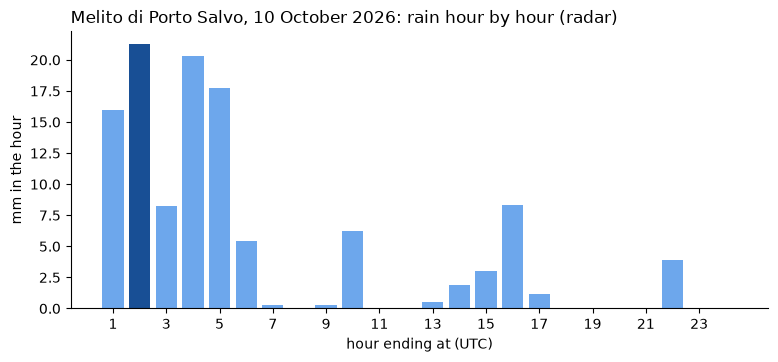

worst hour: the one ending at 02:00 UTC, 21 mm


In [5]:
worst = hours[int(np.argmax(radar_mm))]

fig, ax = plt.subplots(figsize=(9, 3.6))
colours = [BLUE[5] if h == worst else BLUE[2] for h in hours]
ax.bar([h.hour or 24 for h in hours], radar_mm, color=colours, width=0.8)
ax.set_xticks(range(1, 25, 2))
ax.set_xlabel("hour ending at (UTC)")
ax.set_ylabel("mm in the hour")
ax.set_title(f"{PLACE[0]}, {DAY:%d %B %Y}: rain hour by hour (radar)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"worst hour: the one ending at {worst:%H:%M} UTC, {max(radar_mm):.0f} mm")

## 2 · How hard: the rain rate

`SRI` is a picture every five minutes of how hard it is raining, in mm/h. Four frames, fifteen
minutes apart, inside the worst hour: the storm barely moves. A cell that stays over the same
valley is what turns a shower into a flood.

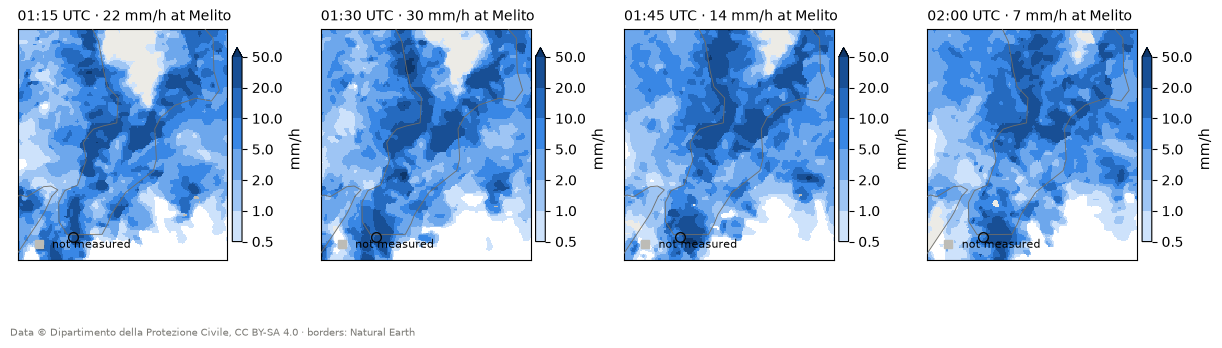

In [6]:
moments = [worst - timedelta(minutes=m) for m in (45, 30, 15, 0)]
async with RadarClient() as radar:
    strip = []
    for moment in moments:
        strip.append(await radar.at("SRI", moment))

fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, moment, frame in zip(axes, moments, strip, strict=True):
    if frame is ABSENT:
        ax.set_axis_off()
        continue
    rain_map(frame, ax, [0.5, 1, 2, 5, 10, 20, 50], box=ZOOM, unit="mm/h")
    rate = frame.sample(point)[0]
    ax.set_title(f"{moment:%H:%M} UTC · {rate or 0:.0f} mm/h at Melito", loc="left", fontsize=10)
    ax.plot(*PLACE[1:], marker="o", ms=7, mfc="none", mec="#0b0b0b", zorder=5)
fig.text(0.12, 0.04, CREDIT, fontsize=7, color="#7a7974")
plt.show()

## 3 · How much: the radar alone against the «Merging»

A radar does not measure rain. It measures the echo of the drops, high above the ground, and
turns it into rain with a formula. On that day, on that slope, it lost more than a third of
the water.

`CUM24` is the «Merging»: the same 24 hours, with the radar map **corrected by the rain
gauges** on the ground. Compare the two at the same point.

In [7]:
async with RadarClient() as radar:
    merging = await radar.at("CUM24", DAY + timedelta(days=1))

merging_mm = merging.sample(point)[0]
print(f"radar alone (24 hourly frames added up) : {sum(radar_mm):6.0f} mm")
print(f"«Merging» (radar + rain gauges)         : {merging_mm:6.0f} mm")
print(f"the radar alone saw {sum(radar_mm) / merging_mm:.0%} of the rain")

radar alone (24 hourly frames added up) :    115 mm
«Merging» (radar + rain gauges)         :    192 mm
the radar alone saw 60% of the rain


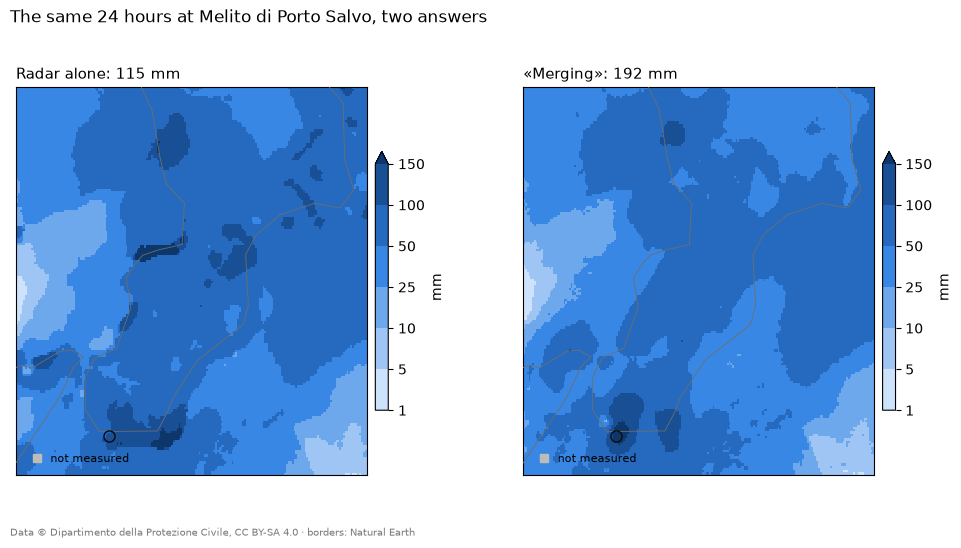

In [8]:
from dataclasses import replace

total = np.sum([f.data for f in hourly.values() if f], axis=0)
radar_day = replace(next(f for f in hourly.values() if f), data=total)
levels = [1, 5, 10, 25, 50, 100, 150]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
rain_map(radar_day, axes[0], levels, box=ZOOM, title=f"Radar alone: {sum(radar_mm):.0f} mm")
rain_map(merging, axes[1], levels, box=ZOOM, title=f"«Merging»: {merging_mm:.0f} mm")
for ax in axes:
    ax.plot(*PLACE[1:], marker="o", ms=8, mfc="none", mec="#0b0b0b", zorder=5)
fig.suptitle(f"The same 24 hours at {PLACE[0]}, two answers", x=0.12, ha="left")
fig.text(0.12, 0.04, CREDIT, fontsize=7, color="#7a7974")
plt.show()

The shape is the same: the radar knows *where*. The amount is not: the gauges know *how
much*. That is the reason to use a «Merging» whenever the question is «how many millimetres».

## Was it a lot?

The forecast said 20 mm. A quick way to see the size of the event: how much land got more
than 100 mm in a day?

In [9]:
top, pixels = merging.peak(ZOOM, threshold=100.0)
print(f"highest value in the box : {top:.0f} mm in 24 hours")
print(f"100 mm or more on        : about {pixels:,} km²")
print(f"at {PLACE[0]}: {merging_mm / 20:.0f} times the 20 mm of the forecast")

highest value in the box : 207 mm in 24 hours
100 mm or more on        : about 770 km²
at Melito di Porto Salvo: 10 times the 20 mm of the forecast


## What you have seen

- `radar.at(product, time)` goes back in time, for about five months;
- `SRT1` and `SRI` tell **when** and **how hard**; a «Merging» (`CUM3` … `CUM24`) tells
  **how much**;
- the radar alone can lose a large part of the rain: never use it for totals when a
  «Merging» exists.

**Next:** [3 · Trust, but verify](03_trust_but_verify.ipynb): what to do when the frame
itself is wrong.

*Radar data © Dipartimento della Protezione Civile, CC BY-SA 4.0.*